In [1]:
import pandas as pd
import numpy as np
import time

# 1. Load data into a DataFrame
filename = "loan.csv"
%time df = pd.read_csv(filename, low_memory=False)

CPU times: user 19.2 s, sys: 15.2 s, total: 34.4 s
Wall time: 35.6 s


In [2]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,NaN,NaN,2500,2500,2500.0,36 months,13.56,84.92,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,30000,30000,30000.0,60 months,18.94,777.23,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,5000,5000,5000.0,36 months,17.97,180.69,D,D1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,4000,4000,4000.0,36 months,18.94,146.51,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,30000,30000,30000.0,60 months,16.14,731.78,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.tail()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
2260663,NaN,NaN,12000,12000,12000.0,60 months,14.08,279.72,C,C3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260664,NaN,NaN,12000,12000,12000.0,60 months,25.82,358.01,E,E4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260665,NaN,NaN,10000,10000,10000.0,36 months,11.99,332.10,B,B5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260666,NaN,NaN,12000,12000,12000.0,60 months,21.45,327.69,D,D5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260667,NaN,NaN,16550,16550,16550.0,60 months,21.45,451.94,D,D5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260668 entries, 0 to 2260667
Columns: 145 entries, id to settlement_term
dtypes: float64(105), int64(4), object(36)
memory usage: 2.4+ GB


In [5]:
df.describe()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,url,dti,...,deferral_term,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term
count,0.0,0.0,2.260668e+06,2.260668e+06,2.260668e+06,2.260668e+06,2.260668e+06,2.260664e+06,0.0,2.258957e+06,...,10613.0,10613.000000,10613.0,10613.000000,8426.000000,10613.000000,10613.000000,33056.000000,33056.000000,33056.000000
mean,NaN,NaN,1.504693e+04,1.504166e+04,1.502344e+04,1.309291e+01,4.458076e+02,7.799243e+04,NaN,1.882420e+01,...,3.0,155.006696,3.0,13.686422,454.840802,11628.036442,193.606331,5030.606922,47.775600,13.148596
std,NaN,NaN,9.190245e+03,9.188413e+03,9.192332e+03,4.832114e+00,2.671737e+02,1.126962e+05,NaN,1.418333e+01,...,0.0,129.113137,0.0,9.728138,375.830737,7615.161123,198.694368,3692.027842,7.336379,8.192319
min,NaN,NaN,5.000000e+02,5.000000e+02,0.000000e+00,5.310000e+00,4.930000e+00,0.000000e+00,NaN,-1.000000e+00,...,3.0,0.640000,3.0,0.000000,1.920000,55.730000,0.010000,44.210000,0.200000,0.000000
25%,NaN,NaN,8.000000e+03,8.000000e+03,8.000000e+03,9.490000e+00,2.516500e+02,4.600000e+04,NaN,1.189000e+01,...,3.0,59.370000,3.0,5.000000,174.967500,5628.730000,43.780000,2227.000000,45.000000,6.000000
50%,NaN,NaN,1.290000e+04,1.287500e+04,1.280000e+04,1.262000e+01,3.779900e+02,6.500000e+04,NaN,1.784000e+01,...,3.0,119.040000,3.0,15.000000,352.605000,10044.220000,132.890000,4172.855000,45.000000,14.000000
75%,NaN,NaN,2.000000e+04,2.000000e+04,2.000000e+04,1.599000e+01,5.933200e+02,9.300000e+04,NaN,2.449000e+01,...,3.0,213.260000,3.0,22.000000,622.792500,16114.940000,284.180000,6870.782500,50.000000,18.000000
max,NaN,NaN,4.000000e+04,4.000000e+04,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,NaN,9.990000e+02,...,3.0,943.940000,3.0,37.000000,2680.890000,40306.410000,1407.860000,33601.000000,521.350000,181.000000


In [6]:
print(list(df.columns))

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_i

In [7]:
df.shape

(2260668, 145)

In [8]:
df['loan_status'].value_counts(dropna=False, normalize=False, ascending=False)

loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31
Name: count, dtype: int64

In [9]:
# 2. Filter for Completed Loans (Target Variable)
print("Filtering target variables...")

# Define mapping for completed and defaulted loans
status_mapping = {
    'Fully Paid': 0,
    'Charged Off': 1,
    'Default': 1
}

# Filter and map
df = df[df['loan_status'].isin(status_mapping.keys())].copy()
df['target'] = df['loan_status'].map(status_mapping)

print(df['target'].value_counts())

Filtering target variables...
target
0    1041952
1     261686
Name: count, dtype: int64


In [10]:
# 3. Drop Data Leakage and Irrelevant Identifiers
# These columns either leak the future or are unique text IDs that models can't use.
columns_to_drop = [
    # Identifiers or Text fields
    'id', 'member_id', 'url', 'desc', 'emp_title', 'title', 'zip_code', 
    # Data Leakage (Future tracking metrics)
    'funded_amnt', 'funded_amnt_inv', 'issue_d', 'out_prncp', 'out_prncp_inv', 
    'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 
    'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 
    'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'loan_status',
    # Hardship or Settlement variables (occur after default begins)
    'hardship_flag', 'hardship_type', 'hardship_reason', 'hardship_status', 
    'deferral_term', 'hardship_amount', 'hardship_start_date', 'hardship_end_date', 
    'payment_plan_start_date', 'hardship_length', 'hardship_dpd', 'hardship_loan_status', 
    'orig_projected_additional_accrued_interest', 'hardship_payoff_balance_amount', 
    'hardship_last_payment_amount', 'debt_settlement_flag', 'debt_settlement_flag_date', 
    'settlement_status', 'settlement_date', 'settlement_amount', 'settlement_percentage', 
    'settlement_term'
]
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1303638 entries, 100 to 2260664
Data columns (total 100 columns):
 #   Column                               Non-Null Count    Dtype  
---  ------                               --------------    -----  
 0   loan_amnt                            1303638 non-null  int64  
 1   term                                 1303638 non-null  object 
 2   int_rate                             1303638 non-null  float64
 3   installment                          1303638 non-null  float64
 4   grade                                1303638 non-null  object 
 5   sub_grade                            1303638 non-null  object 
 6   emp_length                           1228181 non-null  object 
 7   home_ownership                       1303638 non-null  object 
 8   annual_inc                           1303638 non-null  float64
 9   verification_status                  1303638 non-null  object 
 10  pymnt_plan                           1303638 non-null  object 
 11  

In [11]:
df['target'].tail()

2260654    1
2260655    1
2260656    0
2260658    0
2260664    0
Name: target, dtype: int64

In [12]:
print(len(df))

1303638


In [13]:
# 4. Remove columns with >50% missing values
missing_threshold = 0.50 * len(df)
df = df.dropna(thresh=missing_threshold, axis=1).copy()

# Drop zero-variance or single-value columns
df = df.loc[:, df.nunique() > 1]    

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1303638 entries, 100 to 2260664
Data columns (total 65 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   loan_amnt                   1303638 non-null  int64  
 1   term                        1303638 non-null  object 
 2   int_rate                    1303638 non-null  float64
 3   installment                 1303638 non-null  float64
 4   grade                       1303638 non-null  object 
 5   sub_grade                   1303638 non-null  object 
 6   emp_length                  1228181 non-null  object 
 7   home_ownership              1303638 non-null  object 
 8   annual_inc                  1303638 non-null  float64
 9   verification_status         1303638 non-null  object 
 10  purpose                     1303638 non-null  object 
 11  addr_state                  1303638 non-null  object 
 12  dti                         1303326 non-null  float64
 13  

In [14]:
object_cols = df.select_dtypes(include = ['object']).columns.tolist()
# object_cols = df.columns[df.dtypes == 'object'].tolist()       # using Boolean indexing and df.columns

print(object_cols)

['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'application_type', 'disbursement_method']


In [15]:
# Checking the format of data in the object columns so that it can be modified appropriately
# df['term']
# df[['term', 'grade', 'sub_grade']]
df[object_cols]    

,term,grade,sub_grade,emp_length,home_ownership,verification_status,purpose,addr_state,earliest_cr_line,initial_list_status,application_type,disbursement_method
100,36 months,D,D5,5 years,MORTGAGE,Source Verified,debt_consolidation,CA,Jan-2012,w,Joint App,Cash
152,60 months,C,C4,< 1 year,MORTGAGE,Verified,credit_card,OH,Jun-2009,w,Joint App,Cash
170,36 months,A,A3,10+ years,MORTGAGE,Not Verified,credit_card,WA,Feb-1999,w,Joint App,Cash
186,36 months,B,B3,10+ years,RENT,Not Verified,credit_card,TX,Dec-2003,w,Individual,Cash
215,36 months,E,E5,3 years,MORTGAGE,Verified,credit_card,MA,Oct-1997,w,Joint App,Cash
...,...,...,...,...,...,...,...,...,...,...,...,...
2260654,60 months,D,D1,2 years,RENT,Not Verified,debt_consolidation,NY,Dec-2001,f,Individual,Cash
2260655,60 months,F,F4,10+ years,MORTGAGE,Verified,debt_consolidation,TX,Sep-2004,w,Individual,Cash
2260656,60 months,F,F3,10+ years,MORTGAGE,Source Verified,debt_consolidation,IL,Dec-2000,f,Individual,Cash
2260658,60 months,C,C5,< 1 year,RENT,Verified,debt_consolidation,NY,Mar-2001,w,Individual,Cash


In [16]:
df['emp_length'].value_counts()

emp_length
10+ years    428553
2 years      117825
< 1 year     104552
3 years      104204
1 year        85678
5 years       81623
4 years       78033
6 years       60934
8 years       59127
7 years       58148
9 years       49504
Name: count, dtype: int64

In [17]:
# 5. Clean & Engineer Remaining Object Columns
# Convert 'emp_length' to numeric years
if df['emp_length'].dtype == 'object':
    df['emp_length'] = df['emp_length'].str.replace('< 1', '0').str.extract(r'(\d+)').fillna(0).astype(int)

# Extract credit start year from 'earliest_cr_line'
if 'earliest_cr_line' in df.columns:
    df['earliest_cr_year'] = pd.to_datetime(df['earliest_cr_line'], format='%b-%Y', errors='coerce').dt.year
    df = df.drop(columns=['earliest_cr_line'])

# Extract months from 'term'
if df['term'].dtype == 'object':
    df['term'] = df['term'].str.extract(r'(\d+)').astype(float)

# Verify
print("Remaining object columns:", df.select_dtypes(include=['object']).columns.tolist())
print(df[['emp_length', 'earliest_cr_year', 'term']].head())

Remaining object columns: ['grade', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'initial_list_status', 'application_type', 'disbursement_method']
     emp_length  earliest_cr_year  term
100           5              2012  36.0
152           0              2009  60.0
170          10              1999  36.0
186          10              2003  36.0
215           3              1997  36.0


* Now, our remaining object list now contains strictly pure categorical variables.

In [18]:
df.shape
# 65 includes 56 numeric + 9 remaining categorical (object/ text) columns

(1303638, 65)

In [19]:
# 6. Fill Missing Numerical Values
# Select all numerical columns (excluding our target column)
num_cols = df.select_dtypes(include=[np.number]).columns.drop('target', errors='ignore')

# Fill missing values in each numerical column with that column's median
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
# Median has been used for protection from potential outliers present in financial data

# Verify
print("Total missing values remaining:", df.isnull().sum().sum())

Total missing values remaining: 0


In [20]:
rem_obj_cols = df.select_dtypes(include=['object']).columns.tolist()
df[rem_obj_cols]

,grade,sub_grade,home_ownership,verification_status,purpose,addr_state,initial_list_status,application_type,disbursement_method
100,D,D5,MORTGAGE,Source Verified,debt_consolidation,CA,w,Joint App,Cash
152,C,C4,MORTGAGE,Verified,credit_card,OH,w,Joint App,Cash
170,A,A3,MORTGAGE,Not Verified,credit_card,WA,w,Joint App,Cash
186,B,B3,RENT,Not Verified,credit_card,TX,w,Individual,Cash
215,E,E5,MORTGAGE,Verified,credit_card,MA,w,Joint App,Cash
...,...,...,...,...,...,...,...,...,...
2260654,D,D1,RENT,Not Verified,debt_consolidation,NY,f,Individual,Cash
2260655,F,F4,MORTGAGE,Verified,debt_consolidation,TX,w,Individual,Cash
2260656,F,F3,MORTGAGE,Source Verified,debt_consolidation,IL,f,Individual,Cash
2260658,C,C5,RENT,Verified,debt_consolidation,NY,w,Individual,Cash


In [21]:
# Cardinality check: Select all object columns at once and returns a summary table showing the exact number of unique categories in each column.
df.select_dtypes(include=['object']).nunique()   

grade                   7
sub_grade              35
home_ownership          6
verification_status     3
purpose                14
addr_state             51
initial_list_status     2
application_type        2
disbursement_method     2
dtype: int64

In [22]:
# 7. One-Hot Encode Remaining Categorical Columns
# Identify all remaining text ('object') columns
remaining_obj_cols = df.select_dtypes(include=['object']).columns.tolist()
print("Columns being encoded:", remaining_obj_cols)

# Convert text categories into binary (True/False or 1/0) columns
df_encoded = pd.get_dummies(df, columns=remaining_obj_cols, drop_first=True)

# Verify
print("Remaining object columns:", len(df_encoded.select_dtypes(include=['object']).columns))
print("New dataset shape:", df_encoded.shape)      

Columns being encoded: ['grade', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'initial_list_status', 'application_type', 'disbursement_method']
Remaining object columns: 0
New dataset shape: (1303638, 169)


In [23]:
# 8. Optimize Memory and Stratified Train-Test Split
from sklearn.model_selection import train_test_split

# Optimize memory by downcasting float64 -> float32
float64_cols = df_encoded.select_dtypes(include=['float64']).columns
df_encoded[float64_cols] = df_encoded[float64_cols].astype('float32')

# Separate Features (X) and Target (y)
X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

# Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Verify
print(f"X_train shape: {X_train.shape} | Memory: {X_train.memory_usage().sum() / 1024**2:.2f} MB")
print(f"X_test shape:  {X_test.shape}")
print("\nTarget class distribution in y_train:")
print(y_train.value_counts(normalize=True).round(4))

X_train shape: (1042910, 168) | Memory: 351.09 MB
X_test shape:  (260728, 168)

Target class distribution in y_train:
target
0    0.7993
1    0.2007
Name: proportion, dtype: float64


In [24]:
# 9. Train Baseline XGBoost Classifier & Evaluate PR-AUC
# !pip install xgboost
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

# Calculate the exact imbalance ratio
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Calculated scale_pos_weight: {imbalance_ratio:.2f}")

# Initialize the XGBoost Classifier (ML Model)
model = xgb.XGBClassifier(
    n_estimators=200, 
    learning_rate=0.1, 
    max_depth=6, 
    scale_pos_weight=imbalance_ratio, 
    tree_method='hist', 
    random_state=42,
    n_jobs=-1 
)

# Train the model on the training set
print("Training XGBoost model...")
model.fit(X_train, y_train)

# Predict default probabilities on the unseen test set
y_pred_probs = model.predict_proba(X_test)[:, 1] 
y_pred_class = model.predict(X_test) 

# Evaluate using PR-AUC and ROC-AUC
pr_auc = average_precision_score(y_test, y_pred_probs)  
roc_auc = roc_auc_score(y_test, y_pred_probs)  

print(f"\n--- Baseline Model Performance ---")
print(f"PR-AUC Score:  {pr_auc:.4f}  (Baseline random guess = 0.2007)")
print(f"ROC-AUC Score: {roc_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_class))

Calculated scale_pos_weight: 3.98
Training XGBoost model...

--- Baseline Model Performance ---
PR-AUC Score:  0.4066  (Baseline random guess = 0.2007)
ROC-AUC Score: 0.7311

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.66      0.76    208391
           1       0.33      0.68      0.45     52337

    accuracy                           0.66    260728
   macro avg       0.61      0.67      0.60    260728
weighted avg       0.78      0.66      0.69    260728



In [25]:
# 10. Domain Financial Feature Engineering
# Creating copies so our baseline splits remain untouched
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Engineer Four Domain-Specific Financial Ratios
for df_temp in [X_train_fe, X_test_fe]:       
    # Ratio 1: Loan-to-Income Ratio
    df_temp['loan_to_income'] = df_temp['loan_amnt'] / (df_temp['annual_inc'] + 1)    # +1 for protection from division by 0
    
    # Ratio 2: Installment-to-Monthly-Income Ratio 
    monthly_inc = (df_temp['annual_inc'] / 12) + 1
    df_temp['installment_to_income'] = df_temp['installment'] / monthly_inc
    
    # Ratio 3: Credit History Age in Years (Assuming dataset snapshot year ~2019)
    df_temp['credit_age_years'] = 2019 - df_temp['earliest_cr_year']
    
    # Ratio 4: Active Credit Line Ratio
    df_temp['active_acc_ratio'] = df_temp['open_acc'] / (df_temp['total_acc'] + 1)

# Retrain XGBoost with the new engineered features
model_fe = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    scale_pos_weight=imbalance_ratio,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost with engineered features...")
model_fe.fit(X_train_fe, y_train)

# Compare New PR-AUC & ROC-AUC against Baseline
y_pred_probs_fe = model_fe.predict_proba(X_test_fe)[:, 1]
pr_auc_fe = average_precision_score(y_test, y_pred_probs_fe)
roc_auc_fe = roc_auc_score(y_test, y_pred_probs_fe)

print(f"\n--- Feature-Engineered Model Performance ---")
print(f"New PR-AUC Score:  {pr_auc_fe:.4f}  (Baseline was {pr_auc})")
print(f"New ROC-AUC Score: {roc_auc_fe:.4f}  (Baseline was {roc_auc})")

Training XGBoost with engineered features...

--- Feature-Engineered Model Performance ---
New PR-AUC Score:  0.4068  (Baseline was 0.4066)
New ROC-AUC Score: 0.7313  (Baseline was 0.7311)


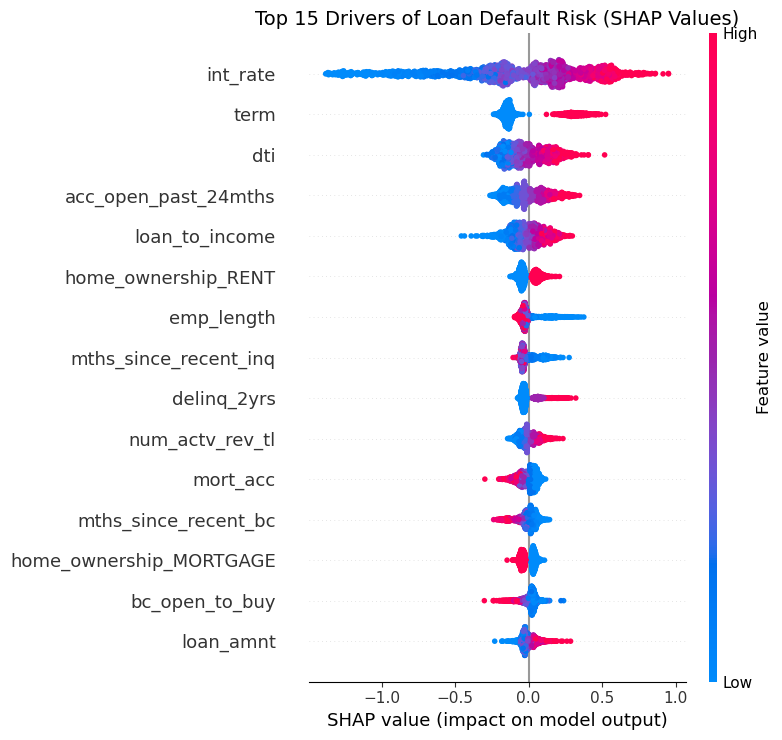

In [26]:
# Step 11: Global Model Explainability with SHAP
# !pip install shap
import shap
import matplotlib.pyplot as plt

# Sample 2,000 test rows (for SHAP to run faster)
X_test_sample = X_test_fe.sample(n=2000, random_state=42)

# Initialize the fast TreeExplainer on our feature-engineered XGBoost model
explainer = shap.TreeExplainer(model_fe)
shap_values = explainer.shap_values(X_test_sample)

# Plot the Top 15 Global Risk Drivers
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, max_display=15, show=False)    # Summary Beeswarm Plot 
plt.title("Top 15 Drivers of Loan Default Risk (SHAP Values)", fontsize=14)
plt.tight_layout()
plt.show()

Inspecting Applicant #268 | Predicted Default Probability: 90.59%


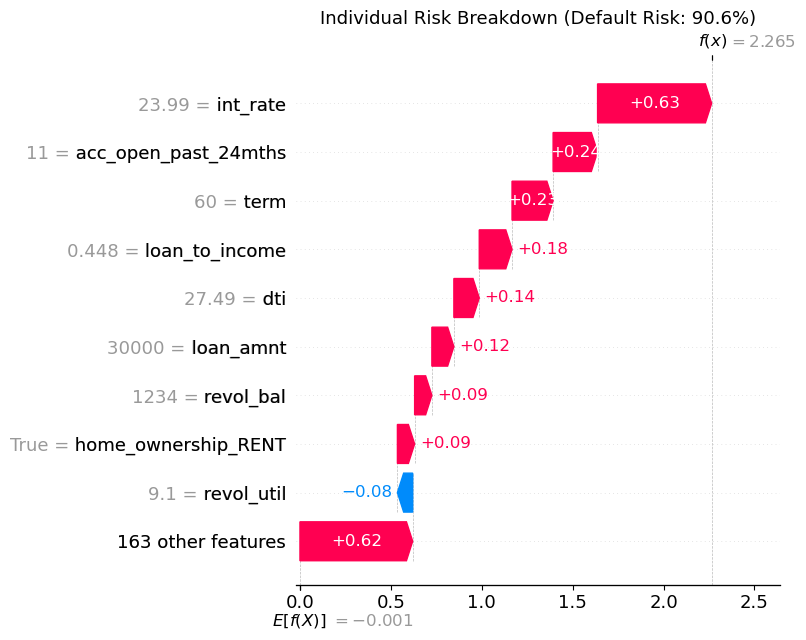

In [27]:
# 12: Individual Applicant Explanation (Waterfall Plot)
# Find the highest-risk applicant inside our 2,000-row sample
sample_probs = model_fe.predict_proba(X_test_sample)[:, 1]
high_risk_idx = sample_probs.argmax()   

print(f"Inspecting Applicant #{high_risk_idx} | Predicted Default Probability: {sample_probs[high_risk_idx]:.2%}")

# Generate a SHAP Explanation object for individual plotting
explanation = shap.Explanation(            
    values=shap_values[high_risk_idx],     
    base_values=explainer.expected_value,  
    data=X_test_sample.iloc[high_risk_idx], 
    feature_names=X_test_sample.columns.tolist() 

# Plot the Waterfall Chart showing exact positive/negative risk factors for this applicant (Individual Waterfall Plot)
plt.figure(figsize=(10, 6))
shap.plots.waterfall(explanation, max_display=10, show=False)   
plt.title(f"Individual Risk Breakdown (Default Risk: {sample_probs[high_risk_idx]:.1%})", fontsize=13)
plt.tight_layout()
plt.show()

 Threshold  Default_Recall  Default_Precision  F1_Score  F2_Score
      0.15          0.9920             0.2131    0.3508    0.5731
      0.20          0.9790             0.2230    0.3632    0.5834
      0.25          0.9574             0.2352    0.3777    0.5932
      0.30          0.9262             0.2501    0.3938    0.6012
      0.35          0.8825             0.2668    0.4097    0.6038
      0.40          0.8263             0.2854    0.4243    0.5992
      0.45          0.7591             0.3071    0.4373    0.5865
      0.50          0.6794             0.3321    0.4461    0.5619
      0.55          0.5864             0.3608    0.4468    0.5213
      0.60          0.4852             0.3940    0.4349    0.4637
      0.65          0.3766             0.4302    0.4016    0.3863
      0.70          0.2714             0.4738    0.3451    0.2968
      0.75          0.1748             0.5285    0.2627    0.2018
      0.80          0.0910             0.5902    0.1578    0.1096
      0.85

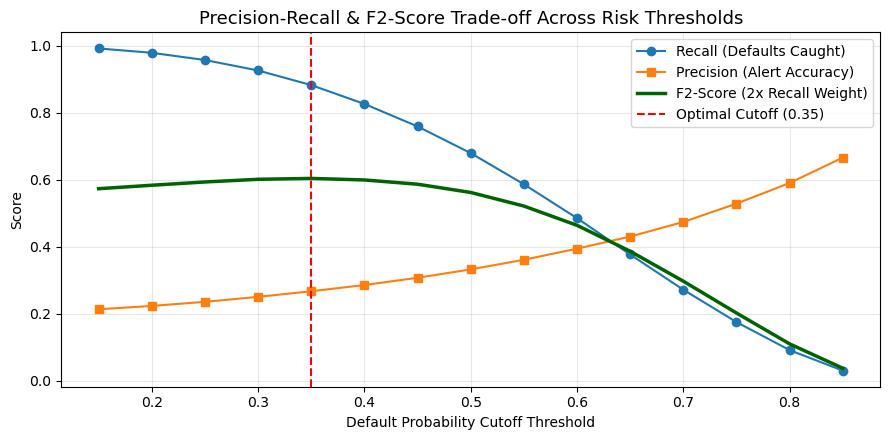

In [29]:
# 13: Decision Threshold Tuning for Business Profit & Recall
# In consumer lending, missing a bad loan (losing the principal) is far more expensive than rejecting a safe borrower (missing out on interest).
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score

# Test thresholds from 0.15 to 0.85
thresholds = np.arange(0.15, 0.86, 0.05)
results = []

for thresh in thresholds:
    y_pred_custom = (y_pred_probs_fe >= thresh).astype(int)
    
    results.append({
        'Threshold': round(thresh, 2),
        'Default_Recall': round(recall_score(y_test, y_pred_custom), 4),
        'Default_Precision': round(precision_score(y_test, y_pred_custom), 4),
        'F1_Score': round(f1_score(y_test, y_pred_custom), 4),
        'F2_Score': round(fbeta_score(y_test, y_pred_custom, beta=2), 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# Identify the optimal threshold maximizing F2-Score
best_row = results_df.loc[results_df['F2_Score'].idxmax()]
print(f"\nOptimal F2 Threshold: {best_row['Threshold']} -> F2-Score: {best_row['F2_Score']:.4f} (Recall: {best_row['Default_Recall']:.2%}, Precision: {best_row['Default_Precision']:.2%})")

# Plot Recall, Precision, and F2-Score across thresholds
plt.figure(figsize=(9, 4.5))
plt.plot(results_df['Threshold'], results_df['Default_Recall'], label='Recall (Defaults Caught)', marker='o')
plt.plot(results_df['Threshold'], results_df['Default_Precision'], label='Precision (Alert Accuracy)', marker='s')
plt.plot(results_df['Threshold'], results_df['F2_Score'], label='F2-Score (2x Recall Weight)', linewidth=2.5, color='darkgreen')
plt.axvline(best_row['Threshold'], color='red', linestyle='--', label=f"Optimal Cutoff ({best_row['Threshold']})")
plt.title("Precision-Recall & F2-Score Trade-off Across Risk Thresholds", fontsize=13)
plt.xlabel("Default Probability Cutoff Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()